In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, classification_report, confusion_matrix
import joblib
import os



# **Raw Data Loading & Filter**

In [ ]:
df = pd.read_csv("../data/Zameen-Updated.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (168446, 20)


,property_id,location_id,page_url,property_type,price,location,city,province_name,latitude,longitude,baths,area,purpose,bedrooms,date_added,agency,agent,Area Type,Area Size,Area Category
0,237062,3325,https://www.zameen.com/Property/g_10_g_10_2_gr...,Flat,10000000,G-10,Islamabad,Islamabad Capital,33.679890,73.012640,2,4 Marla,For Sale,2,2/4/2019,NaN,NaN,Marla,4.0,0-5 Marla
1,346905,3236,https://www.zameen.com/Property/e_11_2_service...,Flat,6900000,E-11,Islamabad,Islamabad Capital,33.700993,72.971492,3,5.6 Marla,For Sale,3,5/4/2019,NaN,NaN,Marla,5.6,5-10 Marla
2,386513,764,https://www.zameen.com/Property/islamabad_g_15...,House,16500000,G-15,Islamabad,Islamabad Capital,33.631486,72.926559,6,8 Marla,For Sale,5,7/17/2019,NaN,NaN,Marla,8.0,5-10 Marla
3,656161,340,https://www.zameen.com/Property/islamabad_bani...,House,43500000,Bani Gala,Islamabad,Islamabad Capital,33.707573,73.151199,4,2 Kanal,For Sale,4,4/5/2019,NaN,NaN,Kanal,2.0,1-5 Kanal
4,841645,3226,https://www.zameen.com/Property/dha_valley_dha...,House,7000000,DHA Defence,Islamabad,Islamabad Capital,33.492591,73.301339,3,8 Marla,For Sale,3,7/10/2019,Easy Property,Muhammad Junaid Ceo Muhammad Shahid Director,Marla,8.0,5-10 Marla


In [3]:
print(df.columns.tolist())

['property_id', 'location_id', 'page_url', 'property_type', 'price', 'location', 'city', 'province_name', 'latitude', 'longitude', 'baths', 'area', 'purpose', 'bedrooms', 'date_added', 'agency', 'agent', 'Area Type', 'Area Size', 'Area Category']


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 168446 entries, 0 to 168445
Data columns (total 20 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   property_id    168446 non-null  int64  
 1   location_id    168446 non-null  int64  
 2   page_url       168446 non-null  str    
 3   property_type  168446 non-null  str    
 4   price          168446 non-null  int64  
 5   location       168446 non-null  str    
 6   city           168446 non-null  str    
 7   province_name  168446 non-null  str    
 8   latitude       168446 non-null  float64
 9   longitude      168446 non-null  float64
 10  baths          168446 non-null  int64  
 11  area           168446 non-null  str    
 12  purpose        168446 non-null  str    
 13  bedrooms       168446 non-null  int64  
 14  date_added     168446 non-null  str    
 15  agency         124375 non-null  str    
 16  agent          124374 non-null  str    
 17  Area Type      168446 non-null  str    


In [5]:
df.isnull().sum()

property_id          0
location_id          0
page_url             0
property_type        0
price                0
location             0
city                 0
province_name        0
latitude             0
longitude            0
baths                0
area                 0
purpose              0
bedrooms             0
date_added           0
agency           44071
agent            44072
Area Type            0
Area Size            0
Area Category        0
dtype: int64

In [13]:
# Karachi filtering
df_karachi = df[df['city'].str.strip().str.lower() == 'karachi'].copy()

# Necessary features filter aur clean numeric conversion
df_karachi = df_karachi[df_karachi['price'] > 0]

# Cleaned data save
df_karachi.to_csv("../data/karachi_properties.csv", index=False)
print("Karachi Dataset Shape:", df_karachi.shape)

Karachi Dataset Shape: (60483, 20)


# **Data Cleaning & Preprocessing**

In [14]:
# 1. Karachi Data Filter
df_karachi = df[df['city'].str.strip().str.lower() == 'karachi'].copy()

# 2. Duplicate rows drop karein
df_karachi = df_karachi.drop_duplicates()

# 3. Missing values clean & handle karein
# Price <= 0 drop karein
df_karachi = df_karachi[df_karachi['price'] > 0]

# Bedrooms aur Baths ki missing values median se fill karein
df_karachi['bedrooms'] = df_karachi['bedrooms'].fillna(df_karachi['bedrooms'].median())
df_karachi['baths'] = df_karachi['baths'].fillna(df_karachi['baths'].median())

# Text columns (agency, agent) ki missing values fill karein
df_karachi['agency'] = df_karachi['agency'].fillna('Unknown Agency')
df_karachi['agent'] = df_karachi['agent'].fillna('Unknown Agent')

# 4. Outliers Handling (Extreme high/low prices filter out karein)
q_low = df_karachi['price'].quantile(0.01)
q_high = df_karachi['price'].quantile(0.99)
df_karachi = df_karachi[(df_karachi['price'] >= q_low) & (df_karachi['price'] <= q_high)]

# Cleaned Dataset Save karein
df_karachi.to_csv("../data/karachi_properties.csv", index=False)
print("Cleaned Karachi Dataset Shape:", df_karachi.shape)
print("Remaining Null Values:\n", df_karachi.isnull().sum())

Cleaned Karachi Dataset Shape: (59357, 20)
Remaining Null Values:
 property_id      0
location_id      0
page_url         0
property_type    0
price            0
location         0
city             0
province_name    0
latitude         0
longitude        0
baths            0
area             0
purpose          0
bedrooms         0
date_added       0
agency           0
agent            0
Area Type        0
Area Size        0
Area Category    0
dtype: int64


# **Exploratory Data Analysis (EDA)**

C:\Users\Aaqeeb Mushtaq\AppData\Local\Temp\ipykernel_9152\3002032232.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_locs.values, y=top_locs.index, palette='crest')


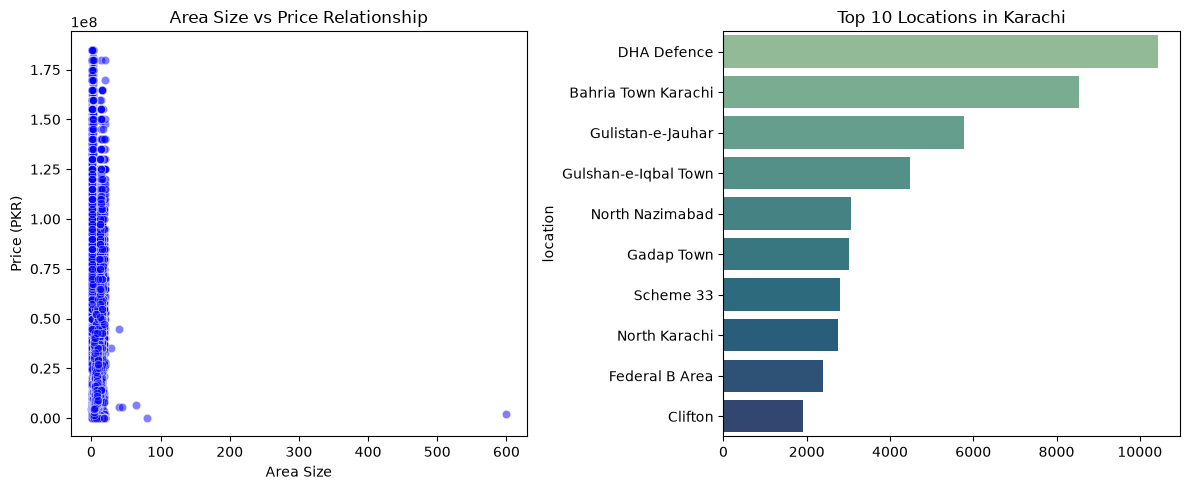

In [15]:
plt.figure(figsize=(12, 5))

# 1. Price vs Area Size Relationship
plt.subplot(1, 2, 1)
sns.scatterplot(data=df_karachi, x='Area Size', y='price', alpha=0.5, color='blue')
plt.title('Area Size vs Price Relationship')
plt.xlabel('Area Size')
plt.ylabel('Price (PKR)')

# 2. Top Locations in Karachi
plt.subplot(1, 2, 2)
top_locs = df_karachi['location'].value_counts().head(10)
sns.barplot(x=top_locs.values, y=top_locs.index, palette='crest')
plt.title('Top 10 Locations in Karachi')

plt.tight_layout()
plt.savefig('../notebooks/karachi_eda.png')
plt.show()

# **Multiple Models Training & Comparison**

In [20]:
# Numeric Features Select karein
features = ['bedrooms', 'baths', 'Area Size', 'latitude', 'longitude']
X = df_karachi[features].fillna(0)
y = df_karachi['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Models comparison
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2 Score": r2_score(y_test, y_pred)
    })

report_df = pd.DataFrame(results)
print("--- MODEL COMPARISON REPORT ---")
print(report_df)

--- MODEL COMPARISON REPORT ---
               Model           MAE          RMSE  R2 Score
0  Linear Regression  1.546356e+07  3.374978e+07 -0.410344
1      Decision Tree  9.858526e+06  2.223208e+07  0.388012
2      Random Forest  9.336042e+06  2.010045e+07  0.499741


# **Confusion Matrix & Best Model Save**

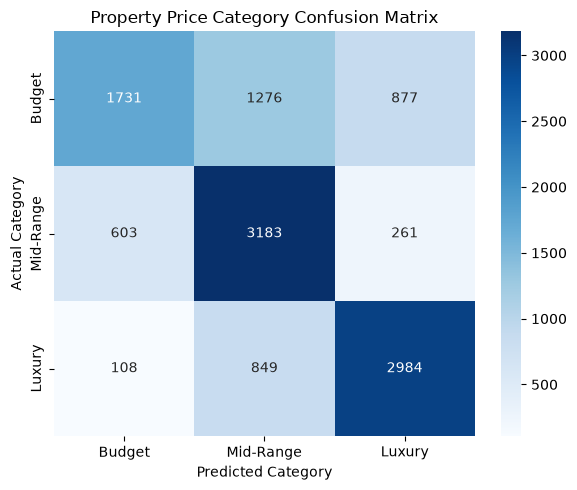

Best Model (Random Forest) saved successfully in models/best_karachi_price_model.pkl!


In [24]:
# 1. Best Model (Random Forest) Pick
best_model = models["Random Forest"]
y_pred_best = best_model.predict(X_test)

# 2. Price Binning for Confusion Matrix
price_bins = [0, y.quantile(0.33), y.quantile(0.66), np.inf]
labels = ['Budget', 'Mid-Range', 'Luxury']

y_test_binned = pd.cut(y_test, bins=price_bins, labels=labels)
y_pred_binned = pd.cut(y_pred_best, bins=price_bins, labels=labels)

cm = confusion_matrix(y_test_binned, y_pred_binned, labels=labels)

# 3. Plot Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Property Price Category Confusion Matrix')
plt.xlabel('Predicted Category')
plt.ylabel('Actual Category')
plt.tight_layout()
plt.savefig('../notebooks/confusion_matrix.png')
plt.show()

# 4. Save Final Best Model with updated name & metadata
os.makedirs('../models', exist_ok=True)

joblib.dump({
    'model': best_model,
    'features': features,
    'model_name': 'Random Forest',
    'evaluation_report': report_df.to_dict()
}, '../models/best_karachi_price_model.pkl')

print("Best Model (Random Forest) saved successfully in models/best_karachi_price_model.pkl!")

In [25]:
# app/recommendation.py


def get_property_recommendations(df, max_budget, location, min_beds):
    filtered = df[(df['price'] <= max_budget) & (df['bedrooms'] >= min_beds)]
    
    if location and location != "All":
        filtered = filtered[filtered['location'].str.contains(location, case=False, na=False)]
        
    results = filtered.head(5).to_dict(orient='records')
    
    # Add Explanation as per requirements
    for item in results:
        item['reason'] = f"Matches your target budget of PKR {max_budget:,.0f} and offers at least {min_beds} bedrooms in {item['location']}."
        
    return results